# Detección de agua e inundación en Lima Sur con Sentinel-1 y U-Net

Pipeline completo del informe (datasets completos, ya no la muestra):

| Ruta | Datos | Uso |
|---|---|---|
| **A** | Sen1Floods11 Colombia, Kuro Siwo (bloque 00), UrbanSARFloods | entrenamiento y validación (partición por eventos) |
| **B** | Sentinel-1 Lima 2017 + EMSN038; Lima Sur 2023 + CONIDA | prueba y aplicación, **sin** reentrenar |
| extra | Sen1Floods11 Bolivia (15 parches manuales) | comparación con la literatura |

Se entrenan dos configuraciones:

* **`agua`** (la del informe): 2 canales (VV, VH durante el evento) → presencia de agua.
* **`cambio`**: 4 canales (VV, VH antes + VV, VH durante) → inundación nueva. Kuro Siwo y UrbanSARFloods traen imagen previa, y Bountos et al. (2024) muestran que apilar fechas es lo que mejor funciona. Además ataca el problema principal de Lima: la arena del desierto es oscura en radar **en ambas fechas**, así que no “cambia”.

> **Qué responde y qué no:** el modelo detecta *dónde hubo agua en superficie en el momento en que pasó el satélite*. No predice lluvia ni pronostica inundaciones futuras.

Todo se configura en `src/config.py`. Con la variable de entorno `PML_RAPIDO=1` el notebook corre de punta a punta en pocos minutos (prueba de humo).

## 0. Entorno

In [1]:
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore", message=".*Measured \\(M\\) geometry.*")

import numpy as np, pandas as pd, torch, rasterio, geopandas as gpd
import matplotlib.pyplot as plt
from src import config as C
from src import datos as D, entrenamiento as E, inferencia as I

C.SALIDA.mkdir(parents=True, exist_ok=True)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
REHACER_PARCHES = False   # True para volver a generar inventario y parches
REENTRENAR = False        # True para reentrenar aunque ya exista el .pt
print(f"datos: {C.DATOS}\nsalida: {C.SALIDA}\ndispositivo: {DISPOSITIVO}"
      + (f" ({torch.cuda.get_device_name(0)})" if DISPOSITIVO == "cuda" else ""))

datos: C:\Ciclo09\MachineLearning\ProyectoMachineLearning\Data
salida: C:\Ciclo09\MachineLearning\ProyectoMachineLearning\Data\procesado
dispositivo: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)


## 1. Inventario de fuentes (Ruta A)
Un registro por archivo / tesela. La partición se asigna por **evento completo** antes de muestrear y de calcular la normalización.

In [2]:
items = D.listar_items()
items.groupby(["particion", "dataset", "evento"]).agg(items=("item", "size"), con_imagen_previa=("tiene_pre", "sum"))

items  con_imagen_previa
particion dataset  evento                                          
train     colombia colombia                  534                  0
          kurosiwo chad                       32                 32
                   harvey                   5001               5001
                   yibuti                     19                 19
          urbansar 20160419_Houston          442                442
                   20161011_Lumberton        191                191
                   20170830_Houston          541                541
                   20180508_Somalia          527                527
                   20190320_Beira            208                208
                   20190329_Iran             517                517
                   20190502_Canada           431                431
                   20191012_Japan            404                404
                   20221013_Niger            501                501
                   20230805_Hebei            933                933
                   20231114_Beledweyne       492                492
val       kurosiwo madagascar_1             1369               1369
                   madagascar_2              682                682
          urbansar 20210319_PortMacquarie    187                187
                   20210324_Sydney           501                501
                   20220302_Coraki           135                135
                   20220705_Sydney           461                461

## 2. Inventario de parches y muestreo por evento
Se recorren solo las etiquetas para conocer la fracción válida y de agua de cada ventana de 256×256. Después se aplica un tope de `MAX_PARCHES_EVENTO` parches por evento con `FRAC_CON_AGUA` de parches con agua, para que Harvey (5 001 teselas) y los chips sin inundación de UrbanSARFloods no dominen.

In [3]:
ruta_inv = C.SALIDA / "inventario.csv"
if ruta_inv.exists() and not REHACER_PARCHES:
    inv = pd.read_csv(ruta_inv)
else:
    inv = D.inventario(items)
    inv.to_csv(ruta_inv, index=False)
seleccion = D.muestrear(inv)
pd.concat({"disponibles": inv.groupby("evento").size(), "elegidos": seleccion.groupby("evento").size(),
           "elegidos_con_agua": seleccion[seleccion.frac_agua > C.FRAC_AGUA_POSITIVO].groupby("evento").size()}, axis=1).fillna(0).astype(int)

,disponibles,elegidos,elegidos_con_agua
evento,,,
20160419_Houston,7072,800,480
20161011_Lumberton,3056,800,237
20170830_Houston,8656,800,480
20180508_Somalia,8432,800,220
20190320_Beira,3328,800,480
20190329_Iran,8272,800,480
20190502_Canada,6896,800,480
20191012_Japan,6464,800,269
20210319_PortMacquarie,2992,800,448


## 3. Extracción de parches
Cada parche `.npz` guarda `img` (VV_pre, VH_pre, VV_post, VH_post en dB, float16), `lab` (0 sin agua, 1 permanente, 2 inundación abierta, 3 urbana), `val` y `val_pre`.

In [4]:
ruta_idx = C.SALIDA / "indice.csv"
if ruta_idx.exists() and not REHACER_PARCHES:
    indice = pd.read_csv(ruta_idx)
else:
    indice = D.extraer_parches(seleccion)
    indice.to_csv(ruta_idx, index=False)
indice.groupby(["particion", "dataset"]).agg(parches=("ruta", "size"), con_pre=("tiene_pre", "sum"),
                                             agua_media=("frac_agua", "mean"), inundacion_media=("frac_inundacion", "mean")).round(3)

parches  con_pre  agua_media  inundacion_media
particion dataset                                                 
train     colombia      796        0       0.144             0.000
          kurosiwo      851      851       0.077             0.059
          urbansar     8082     8082       0.087             0.087
val       kurosiwo     1482     1482       0.208             0.164
          urbansar     2900     2900       0.079             0.079

## 4. Partición y estadísticas de normalización (solo Train)

In [5]:
particion = {k: sorted(g.evento.unique().tolist()) for k, g in indice.groupby("particion")}
json.dump(particion, open(C.SALIDA / "particion.json", "w"), indent=2)
assert not set(particion["train"]) & set(particion["val"]), "un evento aparece en train y val"

ruta_stats = C.SALIDA / "stats.json"
if ruta_stats.exists() and not REHACER_PARCHES:
    stats = json.load(open(ruta_stats))
else:
    stats = D.estadisticas(indice)
    json.dump(stats, open(ruta_stats, "w"), indent=2)
pd.DataFrame(stats).set_index("canales").round(3)

,media,std,pixeles
canales,,,
VV_pre,-9.438,4.306,563289236.0
VH_pre,-15.319,4.675,563289236.0
VV_post,-9.759,4.896,615250393.0
VH_post,-15.573,4.997,615250393.0


## 5. Visualización de parches

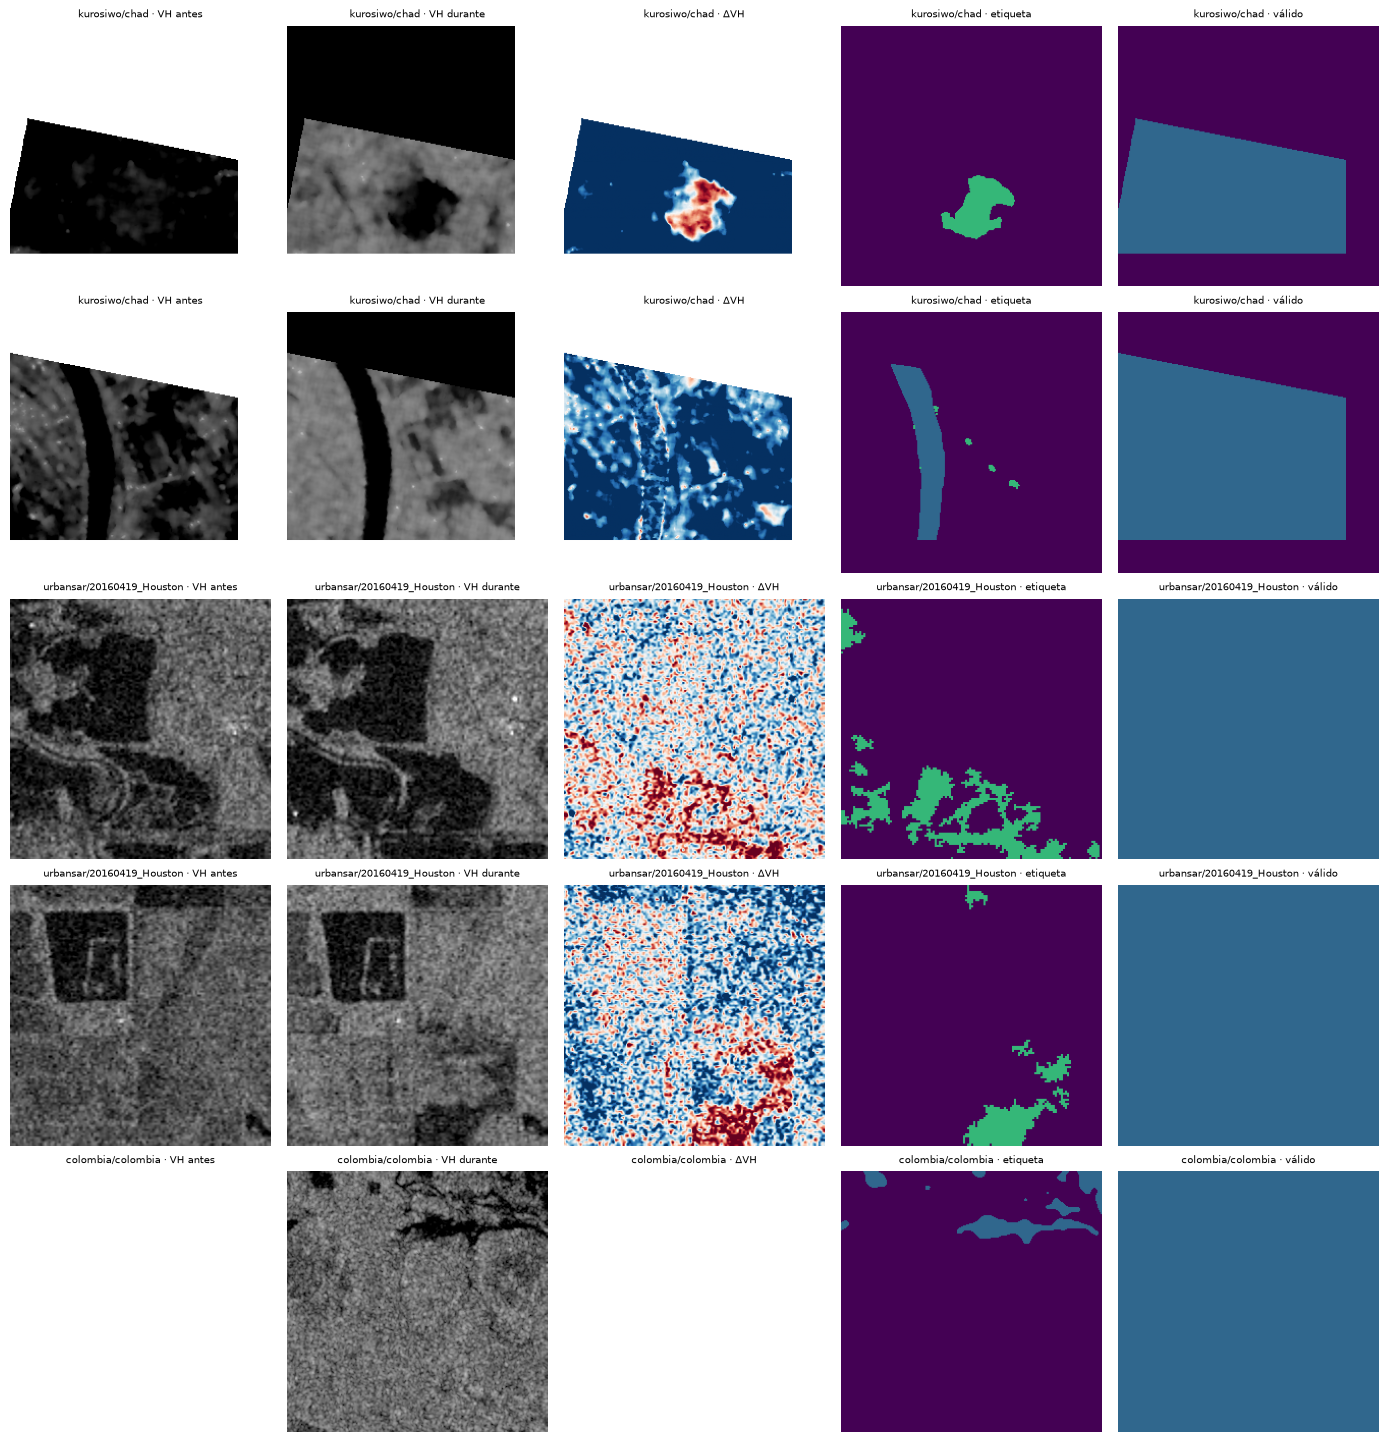

In [6]:
ejemplos = indice[(indice.frac_agua > 0.05) & indice.tiene_pre].groupby("dataset").head(2)
ejemplos = pd.concat([ejemplos, indice[indice.dataset == "colombia"].head(1)])
fig, ejes = plt.subplots(len(ejemplos), 5, figsize=(14, 2.9 * len(ejemplos)))
for fila, e in zip(np.atleast_2d(ejes), ejemplos.itertuples()):
    d = np.load(e.ruta)
    img = d["img"].astype("float32")
    for ax, x, t in zip(fila, [img[1], img[3], img[3] - img[1], d["lab"], d["val"]],
                        ["VH antes", "VH durante", "ΔVH", "etiqueta", "válido"]):
        cm, lo, hi = ("gray", -25, 0) if t.startswith("VH") else ("RdBu", -6, 6) if t == "ΔVH" else ("viridis", 0, 3)
        ax.imshow(x, cmap=cm, vmin=lo, vmax=hi)
        ax.set_title(f"{e.dataset}/{e.evento} · {t}", fontsize=7)
        ax.axis("off")
plt.tight_layout()

## 6. Entrenamiento
Para cada modo y cada encoder (ResNet34, VGG19, EfficientNet-B0, MobileNetV2): U-Net preentrenada en ImageNet, BCE + Dice sobre píxeles válidos, AdamW (lr 1e-4) con reducción en meseta, precisión mixta, lotes con la mitad de parches positivos, rotaciones de 90° y reflexiones, parada temprana por IoU de validación (máximo 10 épocas, paciencia 3).

Según `scripts/evaluar_datos.py`: el modo `agua` excluye Sen1Floods11 Colombia (sus etiquetas Otsu aumentan los falsos positivos en el desierto de Lima) y más datos o más épocas no mejoran la validación.

In [7]:
resultados, historiales = [], []
for modo in C.MODOS:
    train, val = E.filtrar(indice, modo)
    print(f"\n== modo {modo}: train {len(train)} parches ({train.positivo.sum()} positivos) · "
          f"val {len(val)} ({val.positivo.sum()} positivos)")
    for enc in C.ENCODERS:
        ruta_pt = C.SALIDA / "modelos" / f"unet_{modo}_{enc}.pt"
        ruta_h = C.SALIDA / "modelos" / f"historial_{modo}_{enc}.csv"
        if ruta_pt.exists() and ruta_h.exists() and not REENTRENAR:
            h = pd.read_csv(ruta_h)
            mejor = h.loc[h.IoU.idxmax()].drop(["lr", "perdida_train"]).to_dict()
            print(f"{modo} {enc}: ya entrenado (IoU val {mejor['IoU']:.3f})")
        else:
            mejor, h = E.entrenar(enc, modo, train, val, stats, DISPOSITIVO)
            h.to_csv(ruta_h, index=False)
        resultados.append(mejor)
        historiales.append(h)
historial = pd.concat(historiales, ignore_index=True)
historial.to_csv(C.SALIDA / "historial.csv", index=False)


== modo agua: train 8933 parches (4746 positivos) · val 4382 (2040 positivos)


agua   resnet34         época  1 · train 0.920 · val 0.721 · IoU 0.677 · F1 0.807


agua   resnet34         época  2 · train 0.634 · val 0.618 · IoU 0.703 · F1 0.825


agua   resnet34         época  3 · train 0.562 · val 0.624 · IoU 0.678 · F1 0.808


agua   resnet34         época  4 · train 0.531 · val 0.647 · IoU 0.658 · F1 0.794


...

cambio efficientnet-b0  época  6 · train 0.277 · val 0.604 · IoU 0.725 · F1 0.841


cambio mobilenet_v2     época  1 · train 0.689 · val 0.595 · IoU 0.788 · F1 0.881


cambio mobilenet_v2     época  2 · train 0.391 · val 0.556 · IoU 0.764 · F1 0.866


cambio mobilenet_v2     época  3 · train 0.332 · val 0.538 · IoU 0.775 · F1 0.873


cambio mobilenet_v2     época  4 · train 0.303 · val 0.553 · IoU 0.764 · F1 0.866


## 7. Comparación y selección del encoder (solo con validación internacional)

In [8]:
resultados = pd.DataFrame(resultados).sort_values(["modo", "IoU"], ascending=[True, False]).reset_index(drop=True)
resultados.to_csv(C.SALIDA / "resultados_val.csv", index=False)
MEJOR = resultados.groupby("modo").first().encoder.to_dict()
print("Mejor encoder por modo:", MEJOR)
resultados.round(4)

Mejor encoder por modo: {'agua': 'vgg19', 'cambio': 'resnet34'}


,modo,encoder,epoca,perdida_val,IoU,Dice,Precision,Recall,Accuracy
0,agua,vgg19,7,0.6244,0.7092,0.8298,0.8126,0.8478,0.9595
1,agua,resnet34,5,0.6096,0.7070,0.8283,0.8498,0.8079,0.9610
2,agua,efficientnet-b0,1,0.6666,0.7065,0.8280,0.8455,0.8113,0.9607
3,agua,mobilenet_v2,1,0.6987,0.6682,0.8011,0.8129,0.7897,0.9543
4,cambio,resnet34,3,0.5272,0.7880,0.8814,0.9142,0.8508,0.9762
5,cambio,mobilenet_v2,1,0.5953,0.7877,0.8812,0.8818,0.8807,0.9753
6,cambio,vgg19,1,0.5801,0.7787,0.8756,0.8790,0.8722,0.9742
7,cambio,efficientnet-b0,3,0.5520,0.7689,0.8693,0.9007,0.8401,0.9737


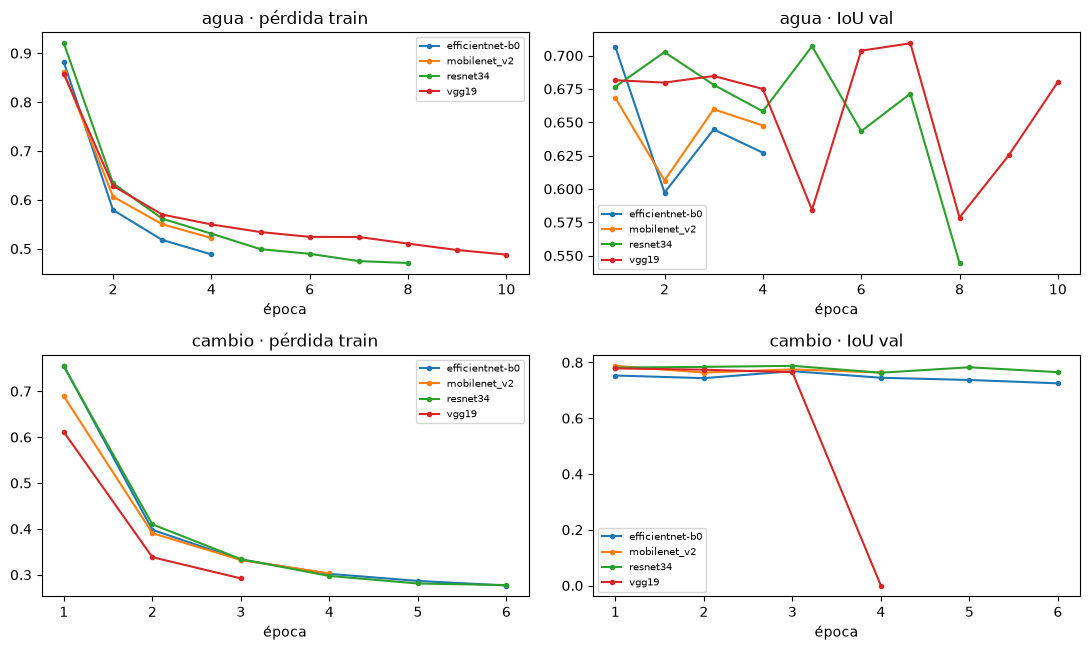

In [9]:
fig, ejes = plt.subplots(len(C.MODOS), 2, figsize=(11, 3.3 * len(C.MODOS)), squeeze=False)
for fila, (modo, gm) in zip(ejes, historial.groupby("modo")):
    for enc, g in gm.groupby("encoder"):
        fila[0].plot(g.epoca, g.perdida_train, marker="o", ms=3, label=enc)
        fila[1].plot(g.epoca, g.IoU, marker="o", ms=3, label=enc)
    fila[0].set_title(f"{modo} · pérdida train"); fila[1].set_title(f"{modo} · IoU val")
    for ax in fila:
        ax.set_xlabel("época"); ax.legend(fontsize=7)
plt.tight_layout()

## 8. Predicciones del mejor modelo en validación

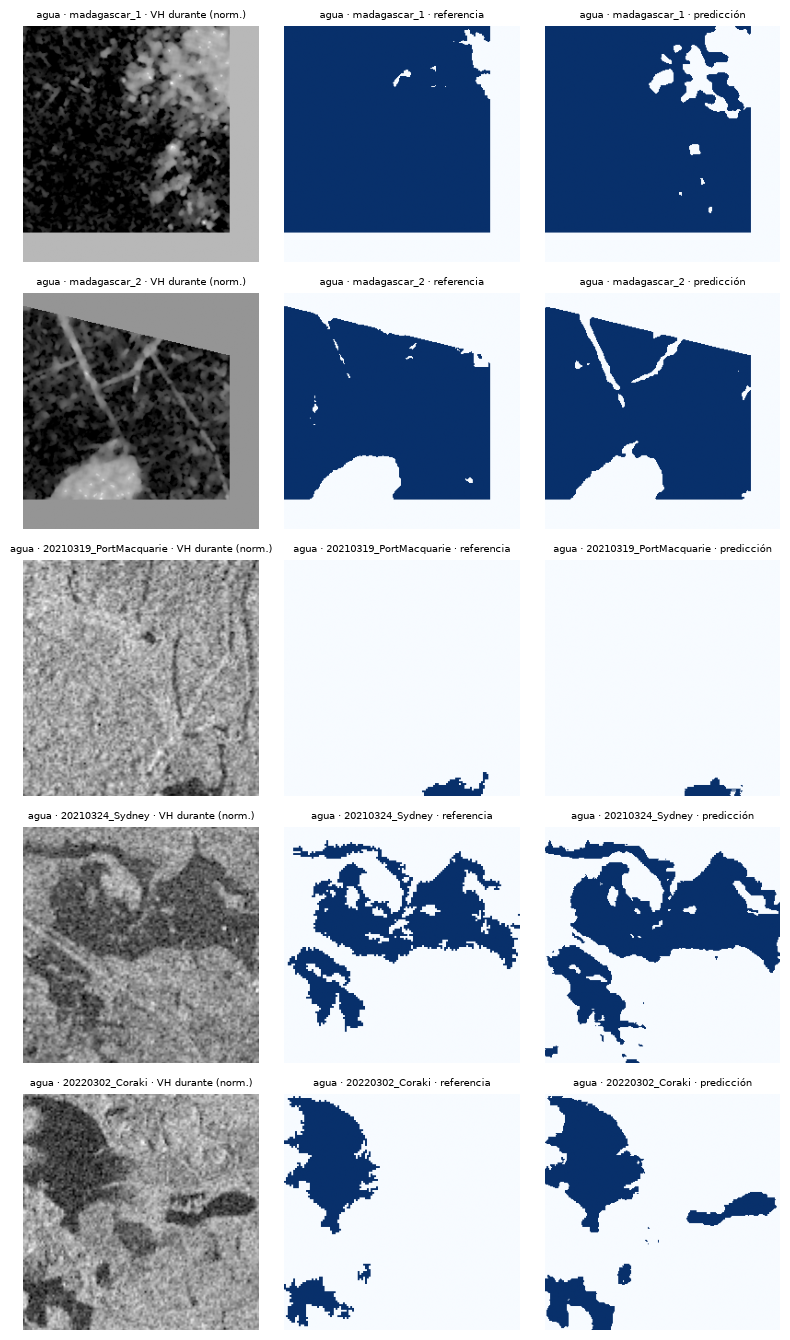

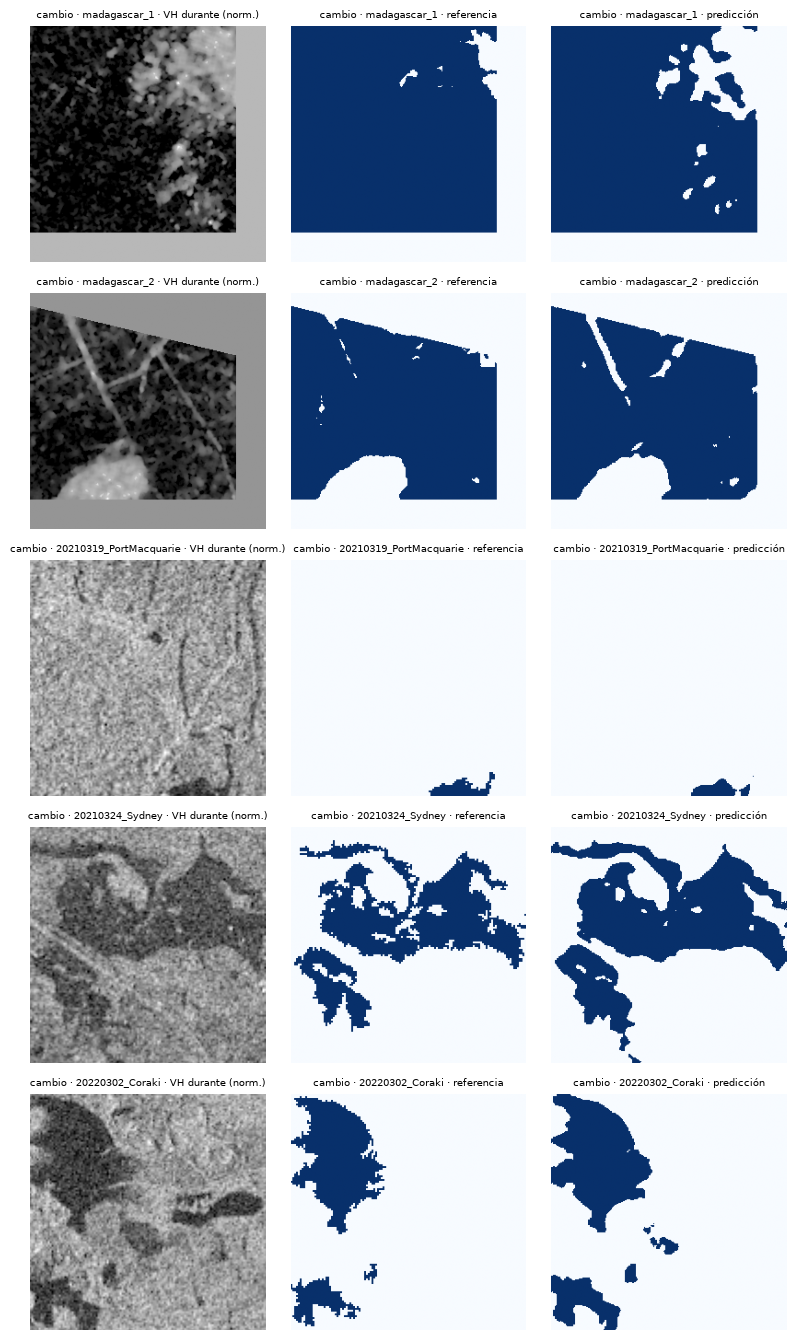

In [10]:
modelos = {m: I.cargar_modelo(m, MEJOR[m], DISPOSITIVO) for m in C.MODOS}
for modo, modelo in modelos.items():
    _, val = E.filtrar(indice, modo)
    ds = E.Parches(val, modo, stats, aumentar=False)
    muestras = val[val.positivo].groupby("evento").head(1).head(5)
    fig, ejes = plt.subplots(len(muestras), 3, figsize=(8, 2.7 * len(muestras)), squeeze=False)
    for fila, (k, e) in zip(ejes, muestras.iterrows()):
        x, y, v = ds[k]
        with torch.no_grad():
            p = torch.sigmoid(modelo(x[None].to(DISPOSITIVO)))[0, 0].cpu().numpy()
        for ax, z, t in zip(fila, [x[-1], y[0], (p >= C.UMBRAL) * v[0].numpy()], ["VH durante (norm.)", "referencia", "predicción"]):
            ax.imshow(z, cmap="gray" if t.startswith("VH") else "Blues"); ax.axis("off")
            ax.set_title(f"{modo} · {e.evento} · {t}", fontsize=7)
    plt.tight_layout(); plt.show()

## 9. Comparación adicional: Sen1Floods11 Bolivia (15 parches con etiqueta manual)
Solo modo `agua` (Bolivia no trae imagen previa). Referencia publicada: IoU de agua total ≈ 0.41 (FCNN, Bonafilia et al., 2020), con otro protocolo — la comparación es orientativa.

In [11]:
filas, c_unet, c_otsu = [], np.zeros(4), np.zeros(4)
for r in sorted((C.BOLIVIA / "S1Hand").glob("*_S1Hand.tif")):
    post, perfil = I.leer_escena(r)
    ref = rasterio.open(C.BOLIVIA / "LabelHand" / r.name.replace("S1Hand", "LabelHand")).read(1)
    prob, valido = I.probabilidad(modelos["agua"], "agua", stats, post, None, DISPOSITIVO)
    m = valido & (ref != -1)
    c_unet += I.conteos(prob[m] >= C.UMBRAL, ref[m] == 1)
    c_otsu += I.conteos(post[1][m] < I.otsu(post[1][m]), ref[m] == 1)
pd.DataFrame([{"metodo": f"U-Net agua {MEJOR['agua']}", **E.metricas(*c_unet)},
              {"metodo": "Otsu VH por parche", **E.metricas(*c_otsu)}]).round(3)

,metodo,IoU,Dice,Precision,Recall,Accuracy
0,U-Net agua vgg19,0.286,0.445,0.848,0.301,0.880
1,Otsu VH por parche,0.384,0.555,0.404,0.886,0.773


## 10. Lima 2017 frente a EMSN038 (prueba externa)

**Advertencia importante.** Las capas usadas como referencia, `Potential_Maximum_flood` (atributo `source`: *river* / *maximun height*) y `Riverbank`, describen la **zona de inundación potencial máxima** y las riberas de los ríos Rímac y Chillón: no son una extensión de agua observada el 17/03/2017. La celda siguiente comprueba que la retrodispersión dentro de esas zonas casi no cambia entre el 05/03 y el 17/03. Por eso las métricas de esta sección miden la coincidencia con una zona de peligro, no el acierto del modelo.

In [12]:
gdb = C.EMSN038
agua_ems = pd.concat([gpd.read_file(gdb, layer=c) for c in ["Potential_Maximum_flood", "Riverbank"]])
zona = gpd.read_file(gdb, layer="EMSN038_AOI").overlay(gpd.read_file(gdb, layer="Footprints"), how="intersection")
post17, perfil17 = I.leer_escena(C.LIMA / "lima_2017_0317.tif")
pre17 = I.leer_en_grilla(C.LIMA / "lima_2017_0305.tif", perfil17)
ref17 = I.rasterizar(agua_ems, perfil17).astype("int16")
ref17[I.rasterizar(zona, perfil17) == 0] = -1
v17 = D.validos_db(post17) & D.validos_db(pre17) & (ref17 != -1)

def pct(x): return np.percentile(x, [10, 50, 90]).round(1).tolist()
pd.DataFrame([{"zona": n, "píxeles": m.sum(), "VH antes p10/50/90": pct(pre17[1][m]),
               "VH durante p10/50/90": pct(post17[1][m]), "ΔVH p10/50/90": pct((post17[1] - pre17[1])[m])}
              for n, m in [("EMSN038 (agua potencial)", v17 & (ref17 == 1)), ("resto del área", v17 & (ref17 == 0))]])

,zona,píxeles,VH antes p10/50/90,VH durante p10/50/90,ΔVH p10/50/90
0,EMSN038 (agua potencial),133831,"[-20.6, -17.0, -11.6]","[-20.8, -16.8, -10.7]","[-2.4, 0.3, 3.1]"
1,resto del área,19173723,"[-22.7, -17.3, -11.3]","[-23.1, -17.4, -11.2]","[-2.3, -0.1, 2.2]"


In [13]:
hand17 = I.a_grilla(C.HAND, perfil17)
bajo = hand17 < C.HAND_MAX
p_agua, _ = I.probabilidad(modelos["agua"], "agua", stats, post17, None, DISPOSITIVO)
p_cambio, _ = I.probabilidad(modelos["cambio"], "cambio", stats, post17, pre17, DISPOSITIVO)
u = I.otsu(post17[1][v17])
dvh = post17[1] - pre17[1]
capas17 = {f"U-Net agua {MEJOR['agua']}": p_agua >= C.UMBRAL,
           f"U-Net agua + HAND<{C.HAND_MAX}": (p_agua >= C.UMBRAL) & bajo,
           f"U-Net cambio {MEJOR['cambio']}": p_cambio >= C.UMBRAL,
           f"U-Net cambio + HAND<{C.HAND_MAX}": (p_cambio >= C.UMBRAL) & bajo,
           f"Otsu VH ({u:.1f} dB)": post17[1] < u,
           f"ΔVH < -3 dB + HAND<{C.HAND_MAX}": (dvh < -3) & bajo}
res17 = I.evaluar_mascaras(capas17, ref17, v17)
res17.round(3)

,metodo,agua_%,IoU,Dice,Precision,Recall,Accuracy
0,U-Net agua vgg19,18.494,0.001,0.002,0.001,0.030,0.809
1,U-Net agua + HAND<10,2.279,0.007,0.014,0.009,0.030,0.971
2,U-Net cambio resnet34,0.002,0.000,0.001,0.156,0.000,0.993
3,U-Net cambio + HAND<10,0.002,0.000,0.001,0.164,0.000,0.993
4,Otsu VH (-17.1 dB),52.172,0.006,0.012,0.006,0.465,0.478
5,ΔVH < -3 dB + HAND<10,1.163,0.024,0.048,0.038,0.064,0.982


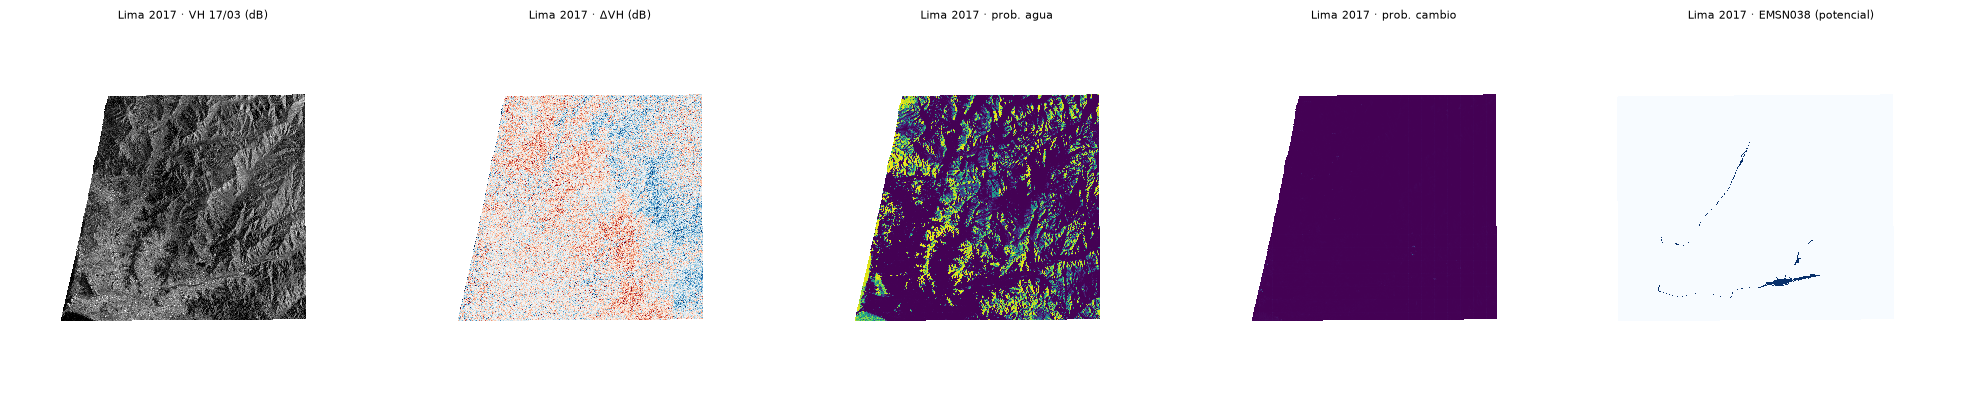

In [14]:
I.mostrar([(np.ma.masked_where(~v17, post17[1]), "VH 17/03 (dB)", "gray", -25, 0),
           (np.ma.masked_where(~v17, dvh), "ΔVH (dB)", "RdBu", -6, 6),
           (np.ma.masked_where(~v17, p_agua), "prob. agua", "viridis", 0, 1),
           (np.ma.masked_where(~v17, p_cambio), "prob. cambio", "viridis", 0, 1),
           (np.ma.masked_where(ref17 == -1, ref17 == 1), "EMSN038 (potencial)", "Blues", 0, 1)], "Lima 2017")

## 11. Aplicación en Lima Sur 2023 (ciclón Yaku)
Imagen del 16/03/2023 (órbita 171 descendente) con la del 04/03/2023 como previa. Se exportan GeoTIFF de probabilidad y máscara para superponerlos en QGIS con los mapas CONIDA georreferenciados. La ocurrencia JRC > 80 % se marca como posible agua permanente (mar, lagunas) y no se cuenta como inundación.

agua (modo agua): 3.95 % · inundación nueva (modo cambio): 0.01 % · oscuro en ambas fechas (arena/sombra): 46.1 %


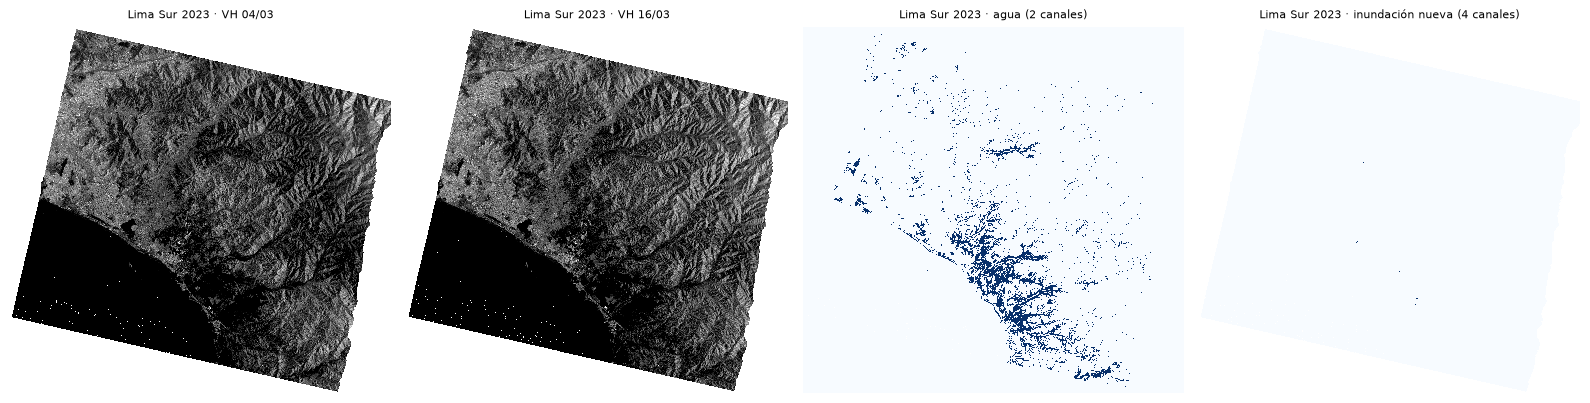

In [15]:
# libera las escenas de 2017 antes de cargar 2023
del post17, pre17, hand17, bajo, p_agua, p_cambio, dvh, capas17
import gc; gc.collect()

post23, perfil23 = I.leer_escena(C.LIMA / "lima_2023_0316.tif")
pre23 = I.leer_en_grilla(C.LIMA / "lima_2023_0304.tif", perfil23)
hand23, jrc23 = I.a_grilla(C.HAND, perfil23), I.a_grilla(C.JRC, perfil23)
permanente = np.nan_to_num(jrc23) > 80
p23_agua, v23_agua = I.probabilidad(modelos["agua"], "agua", stats, post23, None, DISPOSITIVO)
p23_cambio, v23 = I.probabilidad(modelos["cambio"], "cambio", stats, post23, pre23, DISPOSITIVO)
filtro = (hand23 < C.HAND_MAX) & ~permanente
inund23 = (p23_cambio >= C.UMBRAL) & filtro & v23
agua23 = (p23_agua >= C.UMBRAL) & filtro & v23_agua
oscuro_ambas = (post23[1] < -20) & (pre23[1] < -20) & v23

carpeta = C.SALIDA / "predicciones"
I.guardar_tif(carpeta / "lima_2023_0316_prob_agua.tif", np.where(v23_agua, p23_agua, -1), perfil23, "float32", -1)
I.guardar_tif(carpeta / "lima_2023_0316_prob_cambio.tif", np.where(v23, p23_cambio, -1), perfil23, "float32", -1)
I.guardar_tif(carpeta / "lima_2023_0316_inundacion.tif", np.where(v23, inund23, 255), perfil23, "uint8", 255)
I.guardar_tif(carpeta / "lima_2023_0316_agua.tif", np.where(v23_agua, agua23, 255), perfil23, "uint8", 255)
print(f"agua (modo agua): {100 * agua23[v23_agua].mean():.2f} % · inundación nueva (modo cambio): {100 * inund23[v23].mean():.2f} % · "
      f"oscuro en ambas fechas (arena/sombra): {100 * oscuro_ambas[v23].mean():.1f} %")
I.mostrar([(np.ma.masked_where(~v23, pre23[1]), "VH 04/03", "gray", -25, 0),
           (np.ma.masked_where(~v23, post23[1]), "VH 16/03", "gray", -25, 0),
           (np.ma.masked_where(~v23_agua, agua23), "agua (2 canales)", "Blues", 0, 1),
           (np.ma.masked_where(~v23, inund23), "inundación nueva (4 canales)", "Blues", 0, 1)], "Lima Sur 2023")

### 11.1 ¿En qué distritos? Área detectada por distrito (provincia de Lima)

In [16]:
distritos = gpd.read_file(C.EMSN038, layer="Admin_MINAM_BAS_LIM_DISTRITOS")
por_distrito = I.resumen_por_distrito(inund23, v23, perfil23, distritos).merge(
    I.resumen_por_distrito(agua23, v23_agua, perfil23, distritos)[["distrito", "km2_detectados"]]
     .rename(columns={"km2_detectados": "km2_agua_2canales"}), on="distrito", how="left")
por_distrito.to_csv(C.SALIDA / "lima_2023_por_distrito.csv", index=False)
por_distrito.round(3).head(20)

,distrito,km2_observados,km2_detectados,%_detectado,km2_agua_2canales
0,PUNTA NEGRA,129.655,0.050,0.039,20.965
1,PUNTA HERMOSA,121.947,0.050,0.041,27.802
2,LURIN,187.632,0.046,0.025,23.094
3,PACHACAMAC,185.898,0.036,0.019,6.930
4,LURIGANCHO,49.617,0.008,0.015,1.246
5,SAN BARTOLO,53.637,0.006,0.011,14.824
6,EL AGUSTINO,9.279,0.002,0.024,0.483
7,ATE,83.791,0.001,0.001,1.163
8,VILLA EL SALVADOR,33.972,0.000,0.000,0.584
9,SANTA MARIA DEL MAR,7.754,0.000,0.000,2.320


## 12. Lectura de resultados y limitaciones

* Validación internacional alta + prueba en Lima baja = **cambio de dominio**, no necesariamente un mal modelo. Hay que reportarlo así.
* **EMSN038 no es verdad de campo** para el 17/03/2017 (zona potencial + riberas). Recomendación: presentarla como “coincidencia con zonas de peligro” o reemplazarla por polígonos digitalizados de eventos observados (CONIDA, INDECI/SINPAD, notas de prensa con coordenadas).
* **Desierto costero:** buena parte de Lima Sur aparece oscura en VH en *ambas* fechas (arena seca, sombras de radar en laderas). El modelo de 2 canales lo confunde con agua; el de 4 canales lo ve como “sin cambio”.
* **Escala temporal:** los anegamientos y huaicos de Lima Sur duran horas y dejan lodo (que no es oscuro en radar). Sentinel-1 pasa cada 12 días a las ~05:40 h; si la lluvia no coincide con la pasada, el agua ya no está.
* **Resolución:** 10 m es grueso para calles inundadas; la inundación urbana real produce doble rebote (más brillo), que solo se separa bien con coherencia SLC (UrbanSARFloods), no con GRD.
* Para **predecir** zonas propensas (no detectar), se necesitaría otro planteamiento: precipitación (SENAMHI, GPM IMERG, CHIRPS) + susceptibilidad (DEM, pendiente, HAND, quebradas) + inventario histórico de eventos (SIGRID/CENEPRED, INGEMMET) como etiqueta.